<a href="https://colab.research.google.com/github/Edohkindness1/telco_customer_churn_prediction/blob/main/telco_customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
!pip -q install imbalanced-learn xgboost

In [13]:
import pandas as pd

In [14]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

In [15]:
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:
# Turning TotalCharges into numbers; blank text becomes NaN (missing)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [17]:
# How many are missing, and who are they?
print("Missing:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges"]])

Missing: 11
      tenure  MonthlyCharges
488        0           52.55
753        0           20.25
936        0           80.85
1082       0           25.75
1340       0           56.05
3331       0           19.85
3826       0           25.35
4380       0           20.00
5218       0           19.70
6670       0           73.35
6754       0           61.90


In [18]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])                    # just a label, not useful
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})      # words to numbers

print(df.isna().sum().sum())   # this should print 0
df.shape                       # now (7043, 20)

0


(7043, 20)

In [19]:
# to look at class imbalance
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
0,0.73463
1,0.26537


In [20]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])   # the features (inputs)
y = df["Churn"]                  # the target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

In [22]:
# A Quick check
print(make_preprocessor().fit_transform(X_train).shape)

(5634, 45)


In [25]:
# Balance the classes
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

# Ratio of stayers to churners, used by XGBoost's weighting option
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))     # about 2.77

def rf(**kw):
    return RandomForestClassifier(n_estimators=400, max_depth=10, min_samples_leaf=3,
                                  n_jobs=-1, random_state=RANDOM_STATE, **kw)

def xgb(**kw):
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                         subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=-1, **kw)

def build(model, use_smote):
    steps = [("prep", make_preprocessor())]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", model))
    return ImbPipeline(steps)

candidates = {
    "RF + SMOTE":         build(rf(), use_smote=True),
    "RF + class_weight":  build(rf(class_weight="balanced"), use_smote=False),
    "XGB + SMOTE":        build(xgb(), use_smote=True),
    "XGB + scale_pos_wt": build(xgb(scale_pos_weight=spw), use_smote=False),
}

scale_pos_weight: 2.77


In [26]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_rows.append({"Model": name, "CV AUC": scores.mean(), "CV std": scores.std()})
    print(f"{name:20s} {scores.mean():.4f} +/- {scores.std():.4f}")

RF + SMOTE           0.8420 +/- 0.0080
RF + class_weight    0.8447 +/- 0.0091
XGB + SMOTE          0.8431 +/- 0.0093
XGB + scale_pos_wt   0.8442 +/- 0.0097


In [28]:
fitted, test_auc, test_proba = {}, {}, {}
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]     # probability of churn
    fitted[name], test_proba[name] = pipe, proba
    test_auc[name] = roc_auc_score(y_test, proba)

summary = (pd.DataFrame(cv_rows).set_index("Model")
           .assign(**{"Test AUC": pd.Series(test_auc)})
           .sort_values("Test AUC", ascending=False))

best_name = summary.index[0]
print("Best model:", best_name, "| Test AUC:", round(test_auc[best_name], 4))
print("Above 0.80?", test_auc[best_name] > 0.80)
summary.round(4)

Best model: RF + class_weight | Test AUC: 0.8414
Above 0.80? True


,CV AUC,CV std,Test AUC
Model,,,
RF + class_weight,0.8447,0.0091,0.8414
XGB + scale_pos_wt,0.8442,0.0097,0.8404
XGB + SMOTE,0.8431,0.0093,0.8381
RF + SMOTE,0.8420,0.0080,0.8359


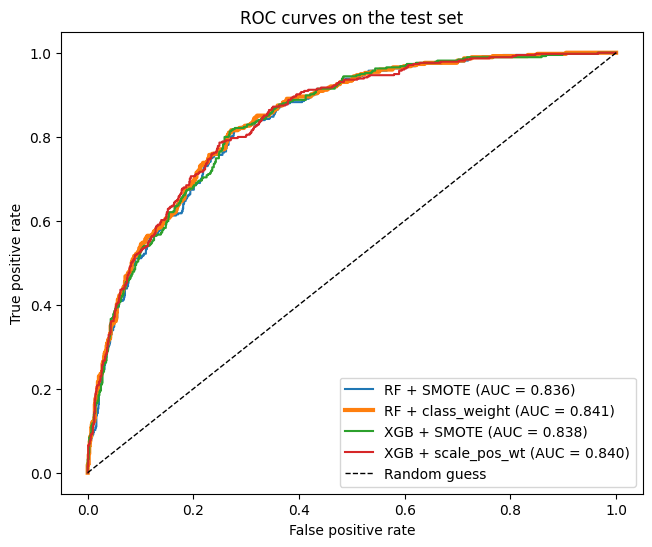

In [30]:
# ROC curves
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(7.5, 6))
for name, proba in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=3 if name == best_name else 1.5,
            label=f"{name} (AUC = {test_auc[name]:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.show()

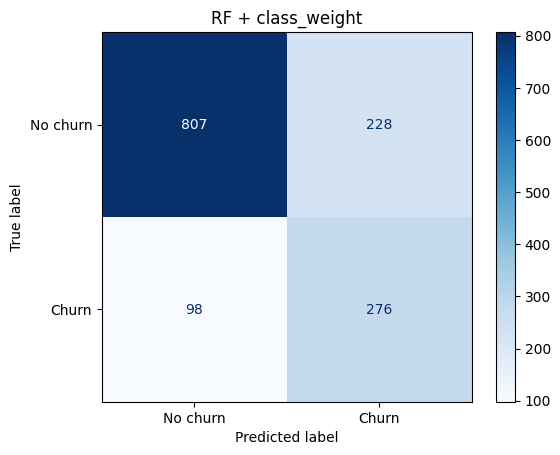

              precision    recall  f1-score   support

    No churn      0.892     0.780     0.832      1035
       Churn      0.548     0.738     0.629       374

    accuracy                          0.769      1409
   macro avg      0.720     0.759     0.730      1409
weighted avg      0.800     0.769     0.778      1409



In [31]:
# confusion matrix and report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

pred = (test_proba[best_name] >= 0.5).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title(best_name)
plt.show()

print(classification_report(y_test, pred, target_names=["No churn", "Churn"], digits=3))

The bottom-right is churners caught, and the bottom-left is churners missed. In the report, look at recall for Churn, the share of real churners the model finds. That number matters most for a retention team.

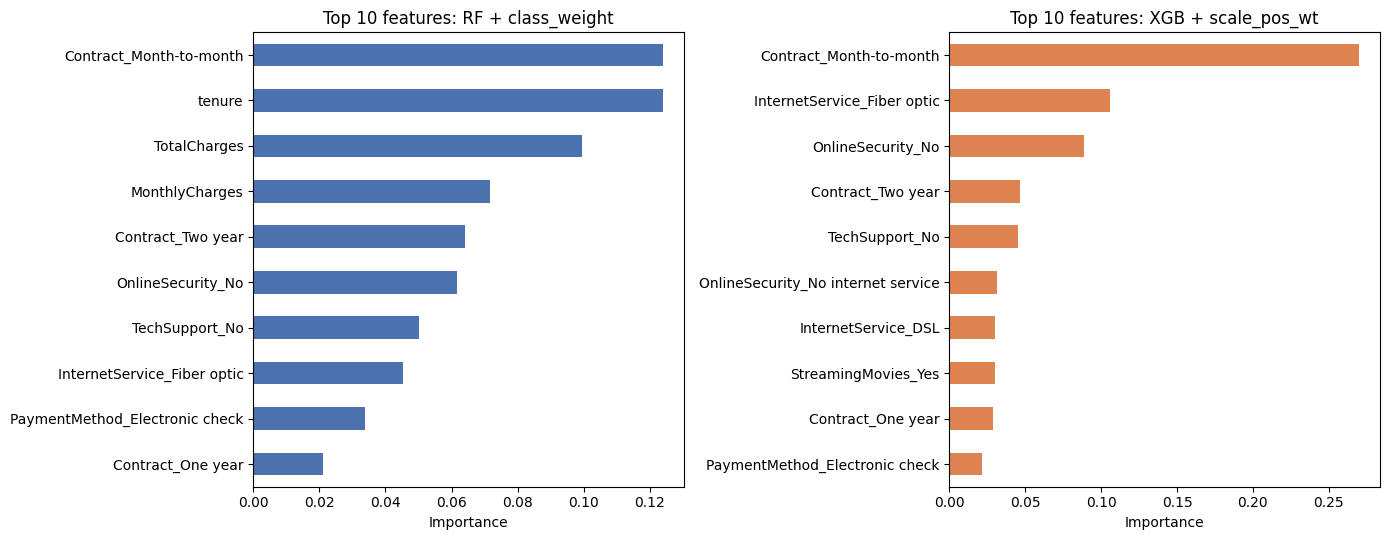

In [33]:
#  top 10 most influential feature importances.
def top_features(pipe, n=10):
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [x.replace("num__", "").replace("cat__", "") for x in names]
    imp = pipe.named_steps["clf"].feature_importances_
    return pd.Series(imp, index=names).sort_values(ascending=False).head(n)

best_rf  = max([n for n in fitted if n.startswith("RF")],  key=test_auc.get)
best_xgb = max([n for n in fitted if n.startswith("XGB")], key=test_auc.get)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name, color in zip(axes, [best_rf, best_xgb], ["#4C72B0", "#DD8452"]):
    top_features(fitted[name]).iloc[::-1].plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Top 10 features: {name}")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()